In [188]:
import numpy as np
import matplotlib.pyplot as plt

In [189]:
def gauss_seidel(A, b, x0, tol=0.5e-6, max_iter=100):
  n = len(b)
  x = x0.copy()
  errors = []
  for k in range(max_iter):
    x_old = x.copy()
    for i in range(n):
      sum_ = sum(A[i][j] * x[j] for j in range(n) if j != i)
      x[i] = (b[i] - sum_) / A[i][i]
    error = np.linalg.norm(x - x_old, ord=np.inf)
    errors.append(error)
    print(f"Iteration {k+1}: x = {x}, Error = {error}")
    if error < tol:
      break
  return x, errors

In [190]:
def rate_of_convergence(errors):
  rates = []
  for i in range(1, len(errors)-1):
    rate = np.log(errors[i+1] / errors[i] / np.log(errors[i] / errors[i-1]))
    rates.append(rate)
  return rates

In [191]:
# Example System
# A = np.array([[10, -1, 2, 0],
#               [-1, 11, -1, 3],
#               [2, -1, 10, -1],
#               [0, 3, -1, 8]], dtype=float)
# b = np.array([6, 25, -11, 15], dtype=float)
A = np.array([[5, -1, 1],
              [2, 8, -1],
              [-4, 1, 10]], dtype=float)
b = np.array([14, -7, 21], dtype=float)
x0 = np.zeros_like(b)

In [192]:
# Solve using Gauss-Seidel
solution, errors = gauss_seidel(A, b, x0)

Iteration 1: x = [ 2.8    -1.575   3.3775], Error = 3.3775
Iteration 2: x = [ 1.8095     -0.9051875   2.91431875], Error = 0.9904999999999999
Iteration 3: x = [ 2.03609875 -1.01973484  3.01641298], Error = 0.22659874999999996
Iteration 4: x = [ 1.99277043 -0.99614099  2.99672227], Error = 0.043328315624999725
Iteration 5: x = [ 2.00142735 -1.00076655  3.00064759], Error = 0.00865691405468727
Iteration 6: x = [ 1.99971717 -0.99984834  2.9998717 ], Error = 0.0017101779793162741
Iteration 7: x = [ 2.00005599 -1.00003003  3.0000254 ], Error = 0.0003388203924958866
Iteration 8: x = [ 1.99998891 -0.99999405  2.99999497], Error = 6.707778768633155e-05
Iteration 9: x = [ 2.0000022  -1.00000118  3.000001  ], Error = 1.3282177608653356e-05
Iteration 10: x = [ 1.99999957 -0.99999977  2.9999998 ], Error = 2.6298990740691863e-06
Iteration 11: x = [ 2.00000009 -1.00000005  3.00000004], Error = 5.207318900524172e-07
Iteration 12: x = [ 1.99999998 -0.99999999  2.99999999], Error = 1.031069449819455e-0

In [193]:
# Compute rate of convergence
roc = rate_of_convergence(errors)
print("Rate of Convergence: ", roc)

Rate of Convergence:  [np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan)]


/tmp/ipykernel_1534/2962329949.py:4: RuntimeWarning: invalid value encountered in log
  rate = np.log(errors[i+1] / errors[i] / np.log(errors[i] / errors[i-1]))


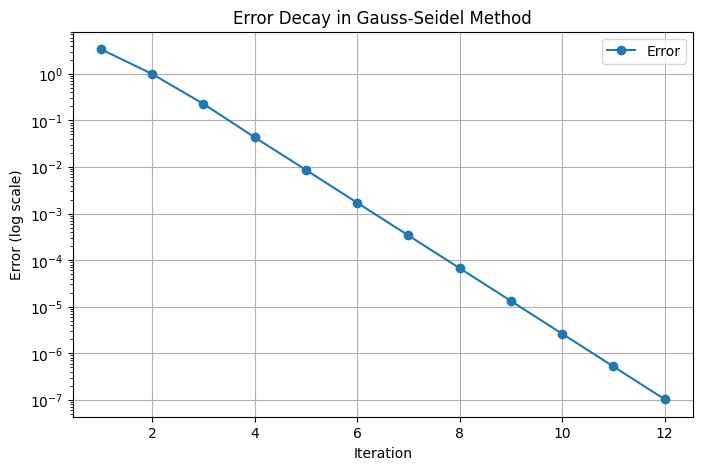

In [194]:
# Plot the error decay
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(errors)+1), errors, marker='o', linestyle='-', label='Error')
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Error (log scale)')
plt.title('Error Decay in Gauss-Seidel Method')
plt.legend()
plt.grid(True)
plt.show()